# Models de Referència (Baseline)

Qualsevol model de forecasting ha de justificar la seva complexitat. Per fer-ho, el primer pas és establir un límit inferior de rendiment: si un model sofisticat no supera el baseline, la complexitat afegida no val la pena.

En aquest notebook entrenem tres models simples sobre les 7 sèries de tecnologies (més el Total) i els avaluem sobre el test set (2025). Els resultats serviran de referència per a tots els models posteriors. En particular, el MASE escala l'error de cada model dividint pel MAE in-sample del Seasonal Naive (calculat sobre el train, és una constant per cada sèrie). Per tant, MASE = 1 significa que el model té el mateix error que el Seasonal Naive tindria sobre el seu propi entrenament; un MASE > 1 indica un model més pobre que aquest baseline històric. Cal tenir en compte que el propi Seasonal Naive avaluat sobre 2025 també pot tenir MASE > 1 si l'any de test és més difícil que la mitjana històrica, com és el cas: la comparació entre models es fa sempre amb els seus MASE de test relatius entre ells.

**Models:**
| Model | Lògica |
|---|---|
| **Seasonal Naive** | Prediu el valor del mateix mes de l'any anterior. Captura l'estacionalitat però no res més. Serveix de referència: el seu MAE in-sample defineix el denominador del MASE. |
| **ETS Additiu** | Holt-Winters amb components additives (error, tendència i estacionalitat sumades). Adient si l'amplitud estacional és relativament constant al llarg del temps. |
| **ETS Multiplicatiu** | Holt-Winters amb components multiplicatives. Adient si l'amplitud de les oscil·lacions creix amb el nivell de la sèrie, un efecte observable en algunes tecnologies en expansió com el vehicle elèctric. |

Esperem que els dos variants ETS millorin el Seasonal Naive (capturen tendència a més d'estacionalitat), i que tots tres quedin per darrere dels models estadístics i de ML que vindran a continuació. Si no fos així, seria un senyal que la complexitat addicional no té valor en aquest problema.

> **Prerequisit:** executar `data_preparation.ipynb` primer.

In [1]:
import sys
sys.path.insert(0, '../../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path

from features import TECNOLOGIES_MODELITZABLES
from evaluation import compute_metrics
from models import SeasonalNaive, ETSForecaster
from plotting import format_ts_ax

DATA_DIR    = Path('../../data/processed')
RESULTS_DIR = DATA_DIR / 'results'
FIGURES_DIR = Path('../../figures')

plt.rcParams.update({'figure.dpi': 120})
TECNOLOGIES = TECNOLOGIES_MODELITZABLES + ['Total']

In [2]:
pivot_train = pd.read_csv(DATA_DIR / 'pivot_train.csv', index_col='date', parse_dates=True)
pivot_test  = pd.read_csv(DATA_DIR / 'pivot_test.csv',  index_col='date', parse_dates=True)
print(f'Train: {pivot_train.index[0].date()} → {pivot_train.index[-1].date()} ({len(pivot_train)} mesos)')
print(f'Test:  {pivot_test.index[0].date()}  → {pivot_test.index[-1].date()}  ({len(pivot_test)} mesos)')
pivot_train.tail(3)

Train: 2017-01-01 → 2024-12-01 (96 mesos)
Test:  2025-01-01  → 2025-12-01  (12 mesos)


,Diesel Mild Hybrid,Diesel/Elèctric Endollable,Elèctric,Gasolina Mild Hybrid,Gasolina/Elèctric,Gasolina/Elèctric Endollable,Total
date,,,,,,,
2024-10-01,302,23,1266,2090,2783,847,7311
2024-11-01,293,22,1176,1813,2374,652,6330
2024-12-01,352,37,1823,2288,2891,781,8173


## 1. Entrenament i predicció sobre el test set


In [3]:
MODELS = {
    'SeasonalNaive':    SeasonalNaive(seasonality=12),
    'ETS_Additiu':      ETSForecaster(error='add', trend='add', seasonal='add'),
    'ETS_Multiplicatiu': ETSForecaster(error='mul', trend='add', seasonal='mul'),
}

H = len(pivot_test)  # 12 mesos

# Seguint la recomanació de l'EDA, apliquem log(y+1) només a ETS_Additiu sobre
# la sèrie Total: és l'altre model lineal (a banda de SARIMA) que no gestiona
# la variança creixent per construcció. SeasonalNaive és trivial i ETS_Mult ja
# té variança multiplicativa nativa.
LOG_COMBOS = {('ETS_Additiu', 'Total')}

forecast_records = []
metrics_records  = []

for tech in TECNOLOGIES:
    y_train = pivot_train[tech].dropna()
    y_test  = pivot_test[tech].values

    for model_name, model in MODELS.items():
        try:
            use_log = (model_name, tech) in LOG_COMBOS
            if use_log:
                y_pred = model.fit_predict(np.log1p(y_train), H)
                y_pred = np.maximum(np.expm1(y_pred), 0)
            else:
                y_pred = model.fit_predict(y_train, H)
                y_pred = np.maximum(y_pred, 0)

            m = compute_metrics(y_test, y_pred, y_train.values)
            m['Tecnologia'] = tech
            m['Model'] = model_name
            metrics_records.append(m)

            for i, date in enumerate(pivot_test.index):
                forecast_records.append({
                    'date': date, 'Tecnologia': tech, 'Model': model_name,
                    'predicted': y_pred[i], 'actual': y_test[i]
                })
        except Exception as e:
            print(f'ERROR {model_name} / {tech}: {e}')

df_metrics   = pd.DataFrame(metrics_records)
df_forecasts = pd.DataFrame(forecast_records)
print(f'Models entrenats: {len(MODELS)} × {len(TECNOLOGIES)} tecnologies '
      f'(log aplicat a {len(LOG_COMBOS)} combinacions)')

Models entrenats: 3 × 7 tecnologies (log aplicat a 1 combinacions)


C:\Users\AgustíCostabella\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:903: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(


## 2. Mètriques sobre el test (2025)


In [4]:
sub = df_metrics[df_metrics['Tecnologia'] != 'Total']
sub_pivot = sub.pivot_table(
    index='Tecnologia', columns='Model',
    values=['RMSE', 'MAPE', 'MASE']
).round(2)
print('Mètriques per sub-tecnologia (6 sèries):')
display(sub_pivot)

tot = df_metrics[df_metrics['Tecnologia'] == 'Total']
tot_pivot = tot.pivot_table(
    index='Tecnologia', columns='Model',
    values=['RMSE', 'MAPE', 'MASE']
).round(2)
print('\nMètriques al Total:')
tot_pivot

Mètriques per sub-tecnologia (6 sèries):


MAPE                                  \
Model                        ETS_Additiu ETS_Multiplicatiu SeasonalNaive   
Tecnologia                                                                 
Diesel Mild Hybrid                 16.83             16.67         13.06   
Diesel/Elèctric Endollable         28.35             49.93         28.35   
Elèctric                           21.88             22.01         34.34   
Gasolina Mild Hybrid               10.97              8.53         18.05   
Gasolina/Elèctric                   7.18              6.19         15.06   
Gasolina/Elèctric Endollable       40.89             43.77         47.10   

                                    MASE                                  \
Model                        ETS_Additiu ETS_Multiplicatiu SeasonalNaive   
Tecnologia                                                                 
Diesel Mild Hybrid                  0.74              0.76          0.64   
Diesel/Elèctric Endollable          1.67              2.86          1.72   
Elèctric                            1.23              1.22          1.82   
Gasolina Mild Hybrid                0.79              0.72          1.49   
Gasolina/Elèctric                   0.60              0.55          1.33   
Gasolina/Elèctric Endollable        4.52              4.77          5.09   

                                    RMSE                                  
Model                        ETS_Additiu ETS_Multiplicatiu SeasonalNaive  
Tecnologia                                                                
Diesel Mild Hybrid                 55.07             57.22         54.92  
Diesel/Elèctric Endollable         18.54             27.83         19.48  
Elèctric                          493.84            493.56        674.40  
Gasolina Mild Hybrid              279.93            220.31        446.72  
Gasolina/Elèctric                 211.90            188.53        455.43  
Gasolina/Elèctric Endollable      658.59            685.59        724.48


Mètriques al Total:


MAPE                                        MASE  \
Model      ETS_Additiu ETS_Multiplicatiu SeasonalNaive ETS_Additiu   
Tecnologia                                                           
Total             8.89             29.59         25.44        0.77   

                                                  RMSE                    \
Model      ETS_Multiplicatiu SeasonalNaive ETS_Additiu ETS_Multiplicatiu   
Tecnologia                                                                 
Total                   2.71          2.34       877.3           2448.58   

                          
Model      SeasonalNaive  
Tecnologia                
Total            2139.76

In [5]:
ranking_total = (
    df_metrics[df_metrics['Tecnologia'] == 'Total']
    .set_index('Model')[['RMSE', 'MAE', 'MAPE', 'MASE']]
    .round(2)
    .sort_values('MASE')
)
print('Rànquing dels 3 baselines sobre la sèrie Total:')
ranking_total

Rànquing dels 3 baselines sobre la sèrie Total:


,RMSE,MAE,MAPE,MASE
Model,,,,
ETS_Additiu,877.30,669.32,8.89,0.77
SeasonalNaive,2139.76,2034.58,25.44,2.34
ETS_Multiplicatiu,2448.58,2353.55,29.59,2.71


## 3. Visualització 


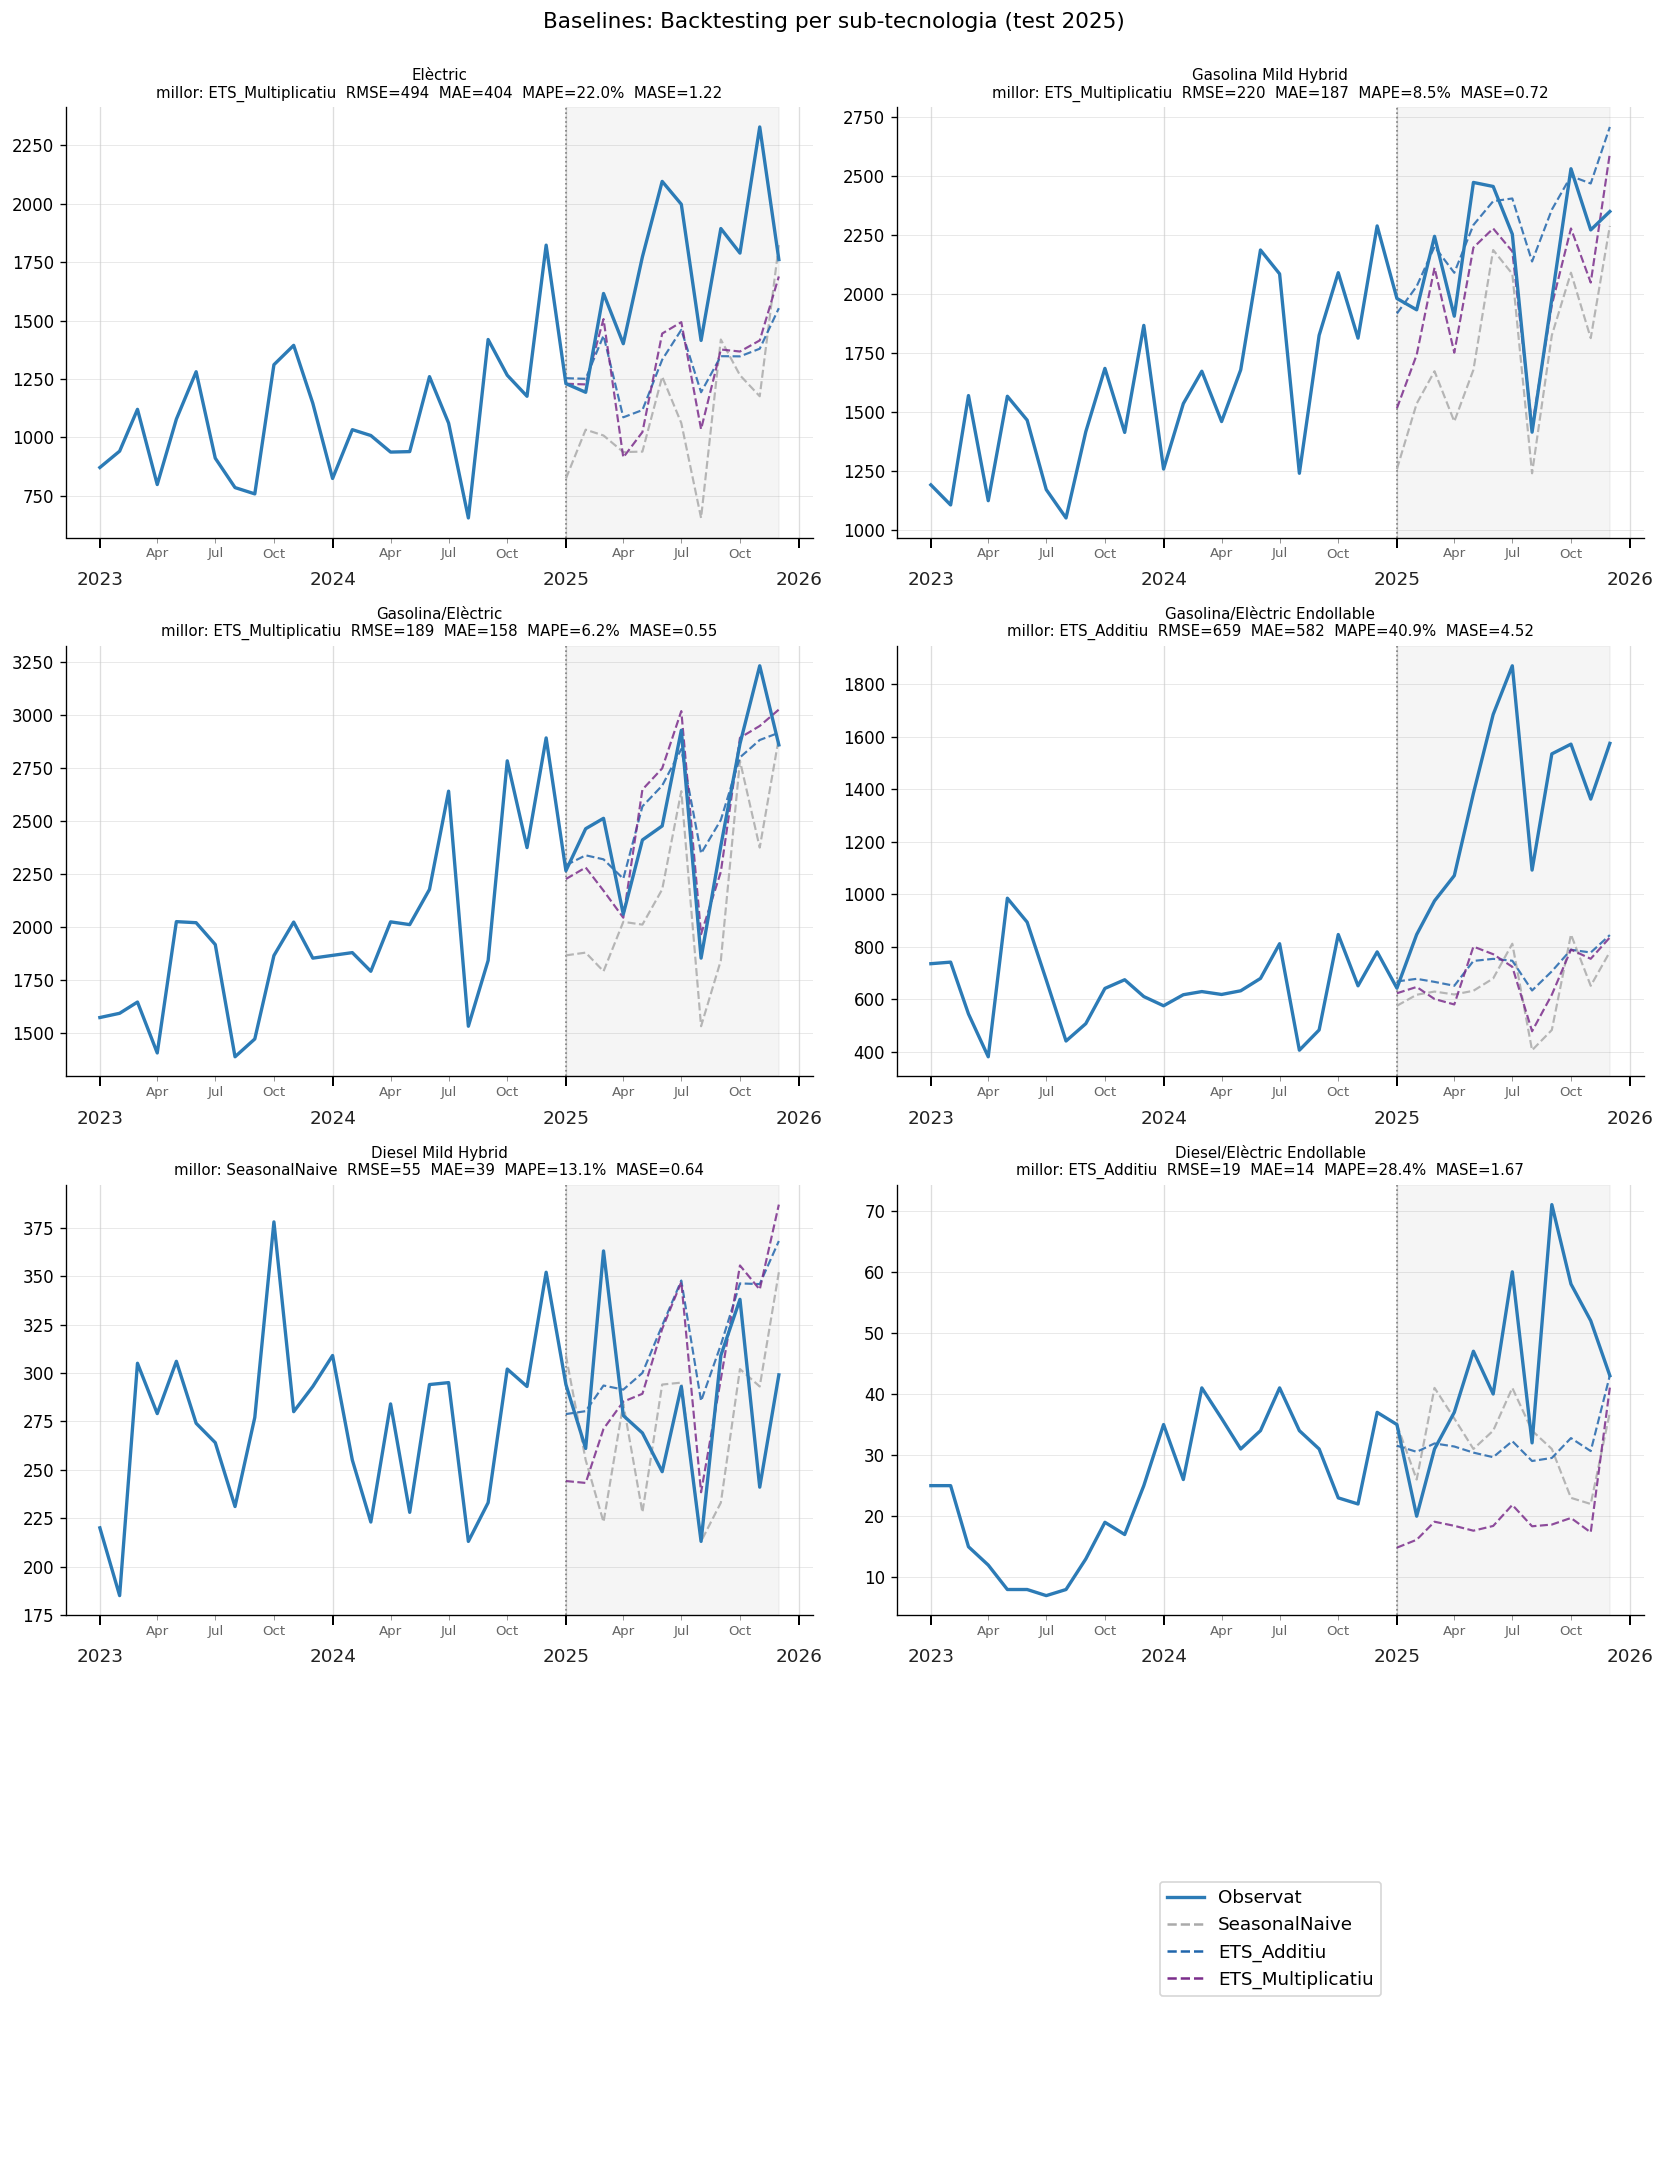

In [6]:
from matplotlib.lines import Line2D

# Per-sub-tecnologia (Total ja té figura dedicada: fig_09_baselines_total.png)
SUB_TECHS = [t for t in TECNOLOGIES if t != 'Total']
colors = {'SeasonalNaive': '#aaaaaa', 'ETS_Additiu': '#2166ac',
          'ETS_Multiplicatiu': '#7b2d8b'}

fig, axes = plt.subplots(4, 2, figsize=(14, 18))
axes_flat = axes.flatten()

for i, tech in enumerate(SUB_TECHS):
    ax = axes_flat[i]
    y_train_plot = pivot_train[tech].iloc[-24:]
    y_test_plot  = pivot_test[tech]
    observed_dates = list(y_train_plot.index) + list(y_test_plot.index)
    observed_vals  = list(y_train_plot.values) + list(y_test_plot.values)
    ax.plot(observed_dates, observed_vals, color='#2c7bb6', lw=2, zorder=10)
    ax.axvspan(pivot_test.index[0], pivot_test.index[-1], alpha=0.08, color='gray')
    ax.axvline(pivot_test.index[0], color='gray', ls=':', lw=1)

    for model_name, c in colors.items():
        sub = df_forecasts[(df_forecasts['Tecnologia'] == tech) &
                           (df_forecasts['Model'] == model_name)].sort_values('date')
        ax.plot(sub['date'], sub['predicted'], color=c, lw=1.3, ls='--', alpha=0.85)

    rows = df_metrics[df_metrics['Tecnologia'] == tech].sort_values('MASE')
    if len(rows):
        best = rows.iloc[0]
        ax.set_title(
            f'{tech}\nmillor: {best["Model"]}  RMSE={best["RMSE"]:.0f}  '
            f'MAE={best["MAE"]:.0f}  MAPE={best["MAPE"]:.1f}%  MASE={best["MASE"]:.2f}',
            fontsize=9)
    else:
        ax.set_title(tech, fontsize=9)
    format_ts_ax(ax)

# Panells no usats (legend al darrer)
for j in range(len(SUB_TECHS), len(axes_flat)):
    axes_flat[j].axis('off')
legend = [Line2D([0], [0], color='#2c7bb6', lw=2, label='Observat')]
for model_name, c in colors.items():
    legend.append(Line2D([0], [0], color=c, lw=1.5, ls='--', label=model_name))
axes_flat[-1].legend(handles=legend, loc='center', fontsize=11)

plt.suptitle('Baselines: Backtesting per sub-tecnologia (test 2025)', fontsize=13, y=1.0)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_baseline_backtest_per_tech.png', bbox_inches='tight')
plt.show()

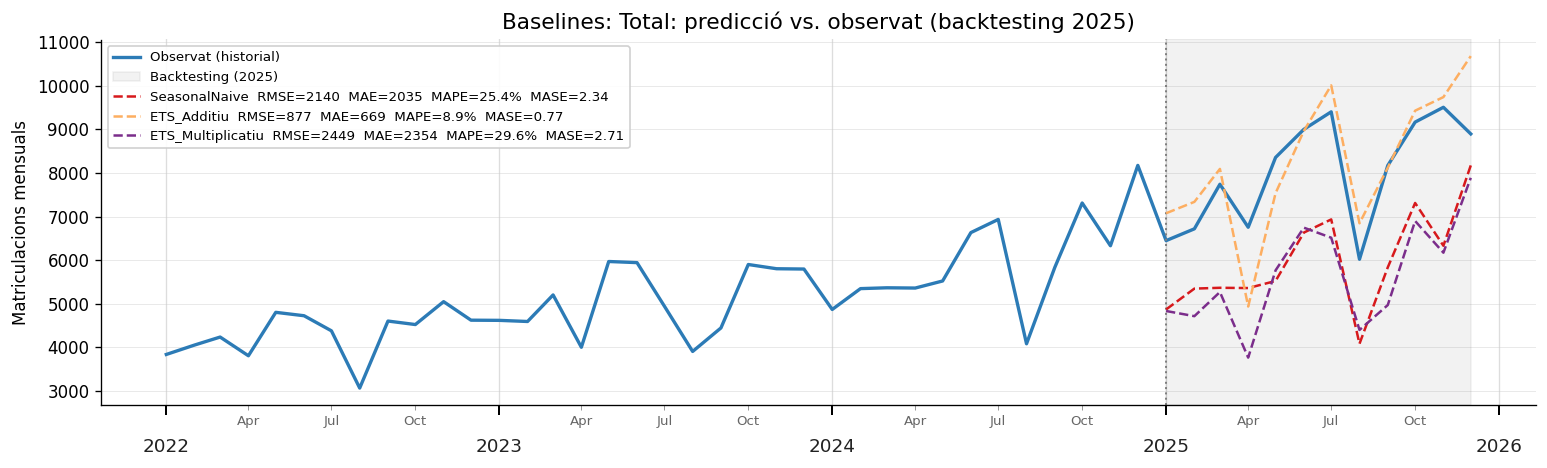

In [7]:
tech = 'Total'
fig, ax = plt.subplots(figsize=(13, 4))

y_train_plot = pivot_train[tech].iloc[-36:]
y_test_plot  = pivot_test[tech]
observed_dates = list(y_train_plot.index) + list(y_test_plot.index)
observed_vals  = list(y_train_plot.values) + list(y_test_plot.values)
ax.plot(observed_dates, observed_vals, color='#2c7bb6', lw=2, label='Observat (historial)')

ax.axvspan(pivot_test.index[0], pivot_test.index[-1], alpha=0.10, color='gray', label='Backtesting (2025)')
ax.axvline(pivot_test.index[0], color='gray', ls=':', lw=1.2)

colors_total = {'SeasonalNaive': '#d7191c', 'ETS_Additiu': '#fdae61',
                'ETS_Multiplicatiu': '#7b2d8b'}
for model_name, color in colors_total.items():
    sub = df_forecasts[(df_forecasts['Tecnologia'] == tech) &
                       (df_forecasts['Model'] == model_name)].sort_values('date')
    row = df_metrics[(df_metrics['Tecnologia'] == tech) &
                     (df_metrics['Model'] == model_name)].iloc[0]
    label = (f'{model_name}  RMSE={row["RMSE"]:.0f}  MAE={row["MAE"]:.0f}  '
             f'MAPE={row["MAPE"]:.1f}%  MASE={row["MASE"]:.2f}')
    ax.plot(sub['date'], sub['predicted'], color=color, lw=1.5, ls='--', label=label)

ax.set_title(f'Baselines: {tech}: predicció vs. observat (backtesting 2025)', fontsize=13)
ax.set_ylabel('Matriculacions mensuals')
ax.legend(fontsize=8, framealpha=0.9)
format_ts_ax(ax)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_09_baselines_total.png', bbox_inches='tight')
plt.show()

## 4. Walk-forward validation (rolling-origin)

El backtest sobre 2025 és una sola realització de l'error. Repliquem l'avaluació amb walk-forward: per a cada sèrie, 13 origins entre el mes 60 i el 96 (`initial=60`, `step=3`, `horizon=12`). Les mètriques mitjanes sobre folds tenen molta menys variància que el holdout únic.

In [8]:
from evaluation import walk_forward_cv_full

# Sèrie completa (train + test): WFV opera sobre tota la història disponible
pivot_full = pd.concat([pivot_train, pivot_test]).sort_index()

def make_fn(model_cls, use_log=False, **kwargs):
    H_LOCAL = 12
    def _fn(train_series):
        m = model_cls(**kwargs)
        if use_log:
            m.fit(np.log1p(train_series))
            return np.maximum(np.expm1(m.predict(H_LOCAL)), 0)
        m.fit(train_series)
        return np.maximum(m.predict(H_LOCAL), 0)
    return _fn

# Map (model_name, tech) -> use_log. Mateix criteri que al backtest.
def needs_log(model_name, tech):
    return (model_name, tech) in LOG_COMBOS

wfv_metric_rows  = []
wfv_forecast_rows = []
print('Walk-forward (initial=60, step=3, horizon=12)...')
for tech in TECNOLOGIES:
    series = pivot_full[tech].dropna()
    for model_name, model_cls_kwargs in [
        ('SeasonalNaive', (SeasonalNaive, dict(seasonality=12))),
        ('ETS_Additiu',   (ETSForecaster, dict(error='add', trend='add', seasonal='add'))),
        ('ETS_Multiplicatiu', (ETSForecaster, dict(error='mul', trend='add', seasonal='mul'))),
    ]:
        cls, kwargs = model_cls_kwargs
        fn = make_fn(cls, use_log=needs_log(model_name, tech), **kwargs)
        m_df, f_df = walk_forward_cv_full(series, fn, initial=60, step=3, horizon=12)
        m_df['Tecnologia'] = tech
        m_df['Model'] = model_name
        f_df['Tecnologia'] = tech
        f_df['Model'] = model_name
        wfv_metric_rows.append(m_df)
        wfv_forecast_rows.append(f_df)
    print(f'  {tech:35s}: ok')

df_wfv_metrics   = pd.concat(wfv_metric_rows, ignore_index=True)
df_wfv_forecasts = pd.concat(wfv_forecast_rows, ignore_index=True)

wfv_agg = (df_wfv_metrics.dropna(subset=['MASE'])
           .groupby(['Tecnologia', 'Model'])[['RMSE', 'MAE', 'MAPE', 'MASE']]
           .mean().round(2).reset_index())
print('\nMitjana WFV per tecnologia × model:')
display(wfv_agg.pivot(index='Tecnologia', columns='Model', values='MASE').round(2))

Walk-forward (initial=60, step=3, horizon=12)...


  Elèctric                           : ok


C:\Users\AgustíCostabella\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:903: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(
C:\Users\AgustíCostabella\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:903: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(
C:\Users\AgustíCostabella\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:903: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(


C:\Users\AgustíCostabella\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:903: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(
C:\Users\AgustíCostabella\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:903: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(
C:\Users\AgustíCostabella\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:903: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(


  Gasolina Mild Hybrid               : ok


...

  Diesel/Elèctric Endollable         : ok


C:\Users\AgustíCostabella\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:903: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(
C:\Users\AgustíCostabella\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:903: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(
C:\Users\AgustíCostabella\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:903: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(
C:\Users\AgustíCostabella\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:903: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(
C:\Users\AgustíCostabella\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:903: ConvergenceWar

  Total                              : ok

Mitjana WFV per tecnologia × model:


C:\Users\AgustíCostabella\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:903: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(


Model,ETS_Additiu,ETS_Multiplicatiu,SeasonalNaive
Tecnologia,,,
Diesel Mild Hybrid,0.68,0.75,0.73
Diesel/Elèctric Endollable,1.44,2.16,1.63
Elèctric,0.72,0.81,0.85
Gasolina Mild Hybrid,0.80,0.75,1.33
Gasolina/Elèctric,0.96,0.98,1.41
Gasolina/Elèctric Endollable,1.69,1.89,1.89
Total,0.97,1.52,1.26


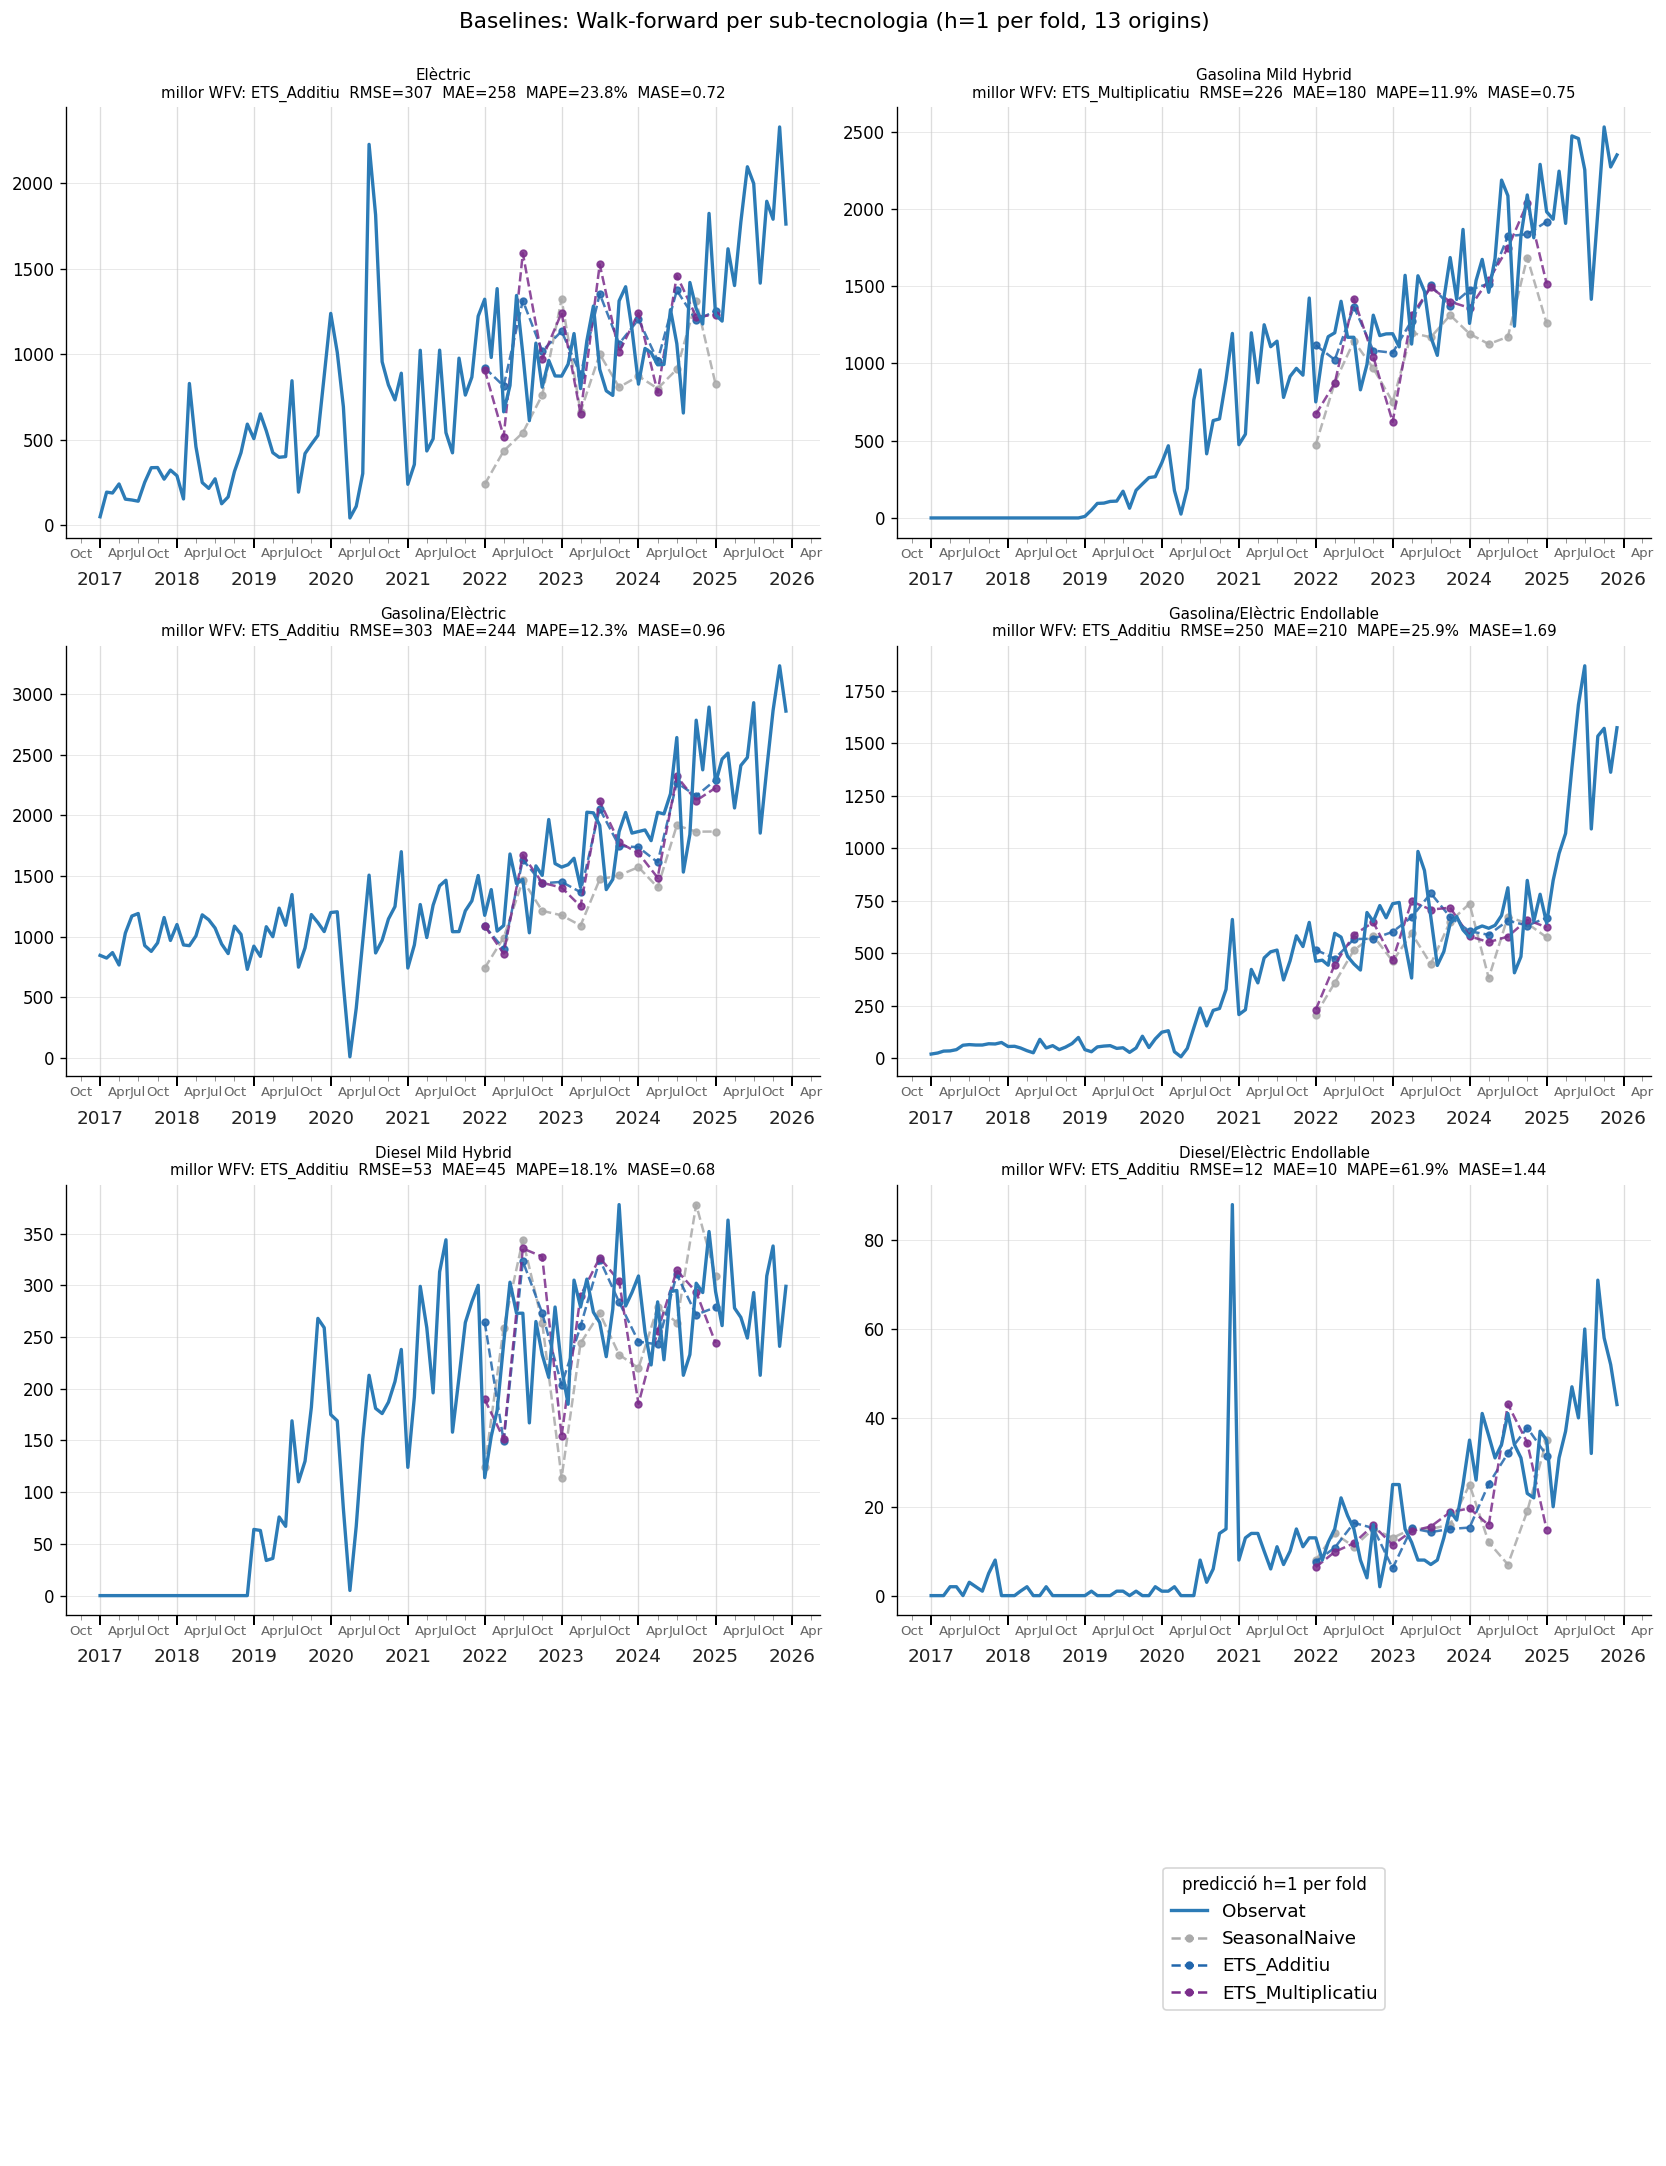

In [9]:
# Visualització WFV per sub-tecnologia (Total ja analitzat separadament)
SUB_TECHS = [t for t in TECNOLOGIES if t != 'Total']
colors_wfv = {'SeasonalNaive': '#aaaaaa', 'ETS_Additiu': '#2166ac',
              'ETS_Multiplicatiu': '#7b2d8b'}

fig, axes = plt.subplots(4, 2, figsize=(14, 18))
axes_flat = axes.flatten()

for i, tech in enumerate(SUB_TECHS):
    ax = axes_flat[i]
    s = pivot_full[tech]
    ax.plot(s.index, s.values, color='#2c7bb6', lw=2, zorder=10)

    for model_name, c in colors_wfv.items():
        sub = df_wfv_forecasts[
            (df_wfv_forecasts['Tecnologia'] == tech)
            & (df_wfv_forecasts['Model'] == model_name)
            & (df_wfv_forecasts['h'] == 1)
        ].sort_values('date')
        ax.plot(pd.to_datetime(sub['date']), sub['predicted'],
                color=c, lw=1.5, ls='--', marker='o', ms=4, alpha=0.85)

    rows = wfv_agg[wfv_agg['Tecnologia'] == tech].sort_values('MASE')
    if len(rows):
        best = rows.iloc[0]
        ax.set_title(
            f'{tech}\nmillor WFV: {best["Model"]}  RMSE={best["RMSE"]:.0f}  '
            f'MAE={best["MAE"]:.0f}  MAPE={best["MAPE"]:.1f}%  MASE={best["MASE"]:.2f}',
            fontsize=9)
    else:
        ax.set_title(tech, fontsize=9)
    format_ts_ax(ax)

for j in range(len(SUB_TECHS), len(axes_flat)):
    axes_flat[j].axis('off')
legend = [Line2D([0], [0], color='#2c7bb6', lw=2, label='Observat')]
for model_name, c in colors_wfv.items():
    legend.append(Line2D([0], [0], color=c, lw=1.5, ls='--', marker='o', ms=4,
                         label=model_name))
axes_flat[-1].legend(handles=legend, loc='center', fontsize=11,
                     title='predicció h=1 per fold')

plt.suptitle('Baselines: Walk-forward per sub-tecnologia (h=1 per fold, 13 origins)',
             fontsize=13, y=1.0)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_baseline_wfv_per_tech.png', bbox_inches='tight')
plt.show()

## 5. Guardar resultats


In [10]:
df_forecasts.to_csv(RESULTS_DIR / 'baseline_forecasts.csv', index=False)
df_metrics.to_csv(RESULTS_DIR / 'baseline_metrics.csv', index=False)
df_wfv_metrics.to_csv(RESULTS_DIR / 'baseline_wfv_metrics.csv', index=False)
df_wfv_forecasts.to_csv(RESULTS_DIR / 'baseline_wfv_forecasts.csv', index=False)
print('Guardats:')
print('  baseline_forecasts.csv, baseline_metrics.csv')
print('  baseline_wfv_metrics.csv, baseline_wfv_forecasts.csv')

Guardats:
  baseline_forecasts.csv, baseline_metrics.csv
  baseline_wfv_metrics.csv, baseline_wfv_forecasts.csv
